<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day24_Mitigation_Minimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()

Saving preregistration.json to preregistration.json
Saving final_config.json to final_config.json
Saving train.csv to train.csv


{'preregistration.json': b'{\n  "created": "2026-10-30T09:58:25",\n  "n_test_assumed": 72,\n  "regression": {\n    "early (no G1/G2)": {\n      "model": "Ridge",\n      "expected_rmse": 2.959,\n      "expected_range_95": [\n        2.482661817414654,\n        3.380634483890643\n      ]\n    },\n    "all features": {\n      "model": "Ridge",\n      "expected_rmse": 0.916,\n      "expected_range_95": [\n        0.7638558293208028,\n        1.0395304452064604\n      ]\n    }\n  },\n  "classification": {\n    "early (no G1/G2)": {\n      "model": "Logistic",\n      "expected_auc": 0.657,\n      "expected_range_95": [\n        0.5090681818181819,\n        0.8226607407788004\n      ],\n      "threshold": 0.12,\n      "train_oof_recall": 0.821917808219178,\n      "train_oof_precision": 0.2777777777777778,\n      "train_oof_flagged_share": 0.7578947368421053\n    },\n    "all features": {\n      "model": "Logistic",\n      "expected_auc": 0.943,\n      "expected_range_95": [\n        0.8996641

In [2]:
# Upload the file into Colab
from google.colab import files
files.upload()

Saving fairness_threshold_tradeoff.csv to fairness_threshold_tradeoff.csv
Saving fairness_regression_gaps.csv to fairness_regression_gaps.csv
Saving fairness_proxy_check.csv to fairness_proxy_check.csv
Saving fairness_group_sizes.csv to fairness_group_sizes.csv
Saving fairness_classification_groups.csv to fairness_classification_groups.csv
Saving fairness_classification_gaps.csv to fairness_classification_gaps.csv
Saving model_meta.json to model_meta.json
Saving test_results_regression.csv to test_results_regression.csv
Saving test_results_classification.csv to test_results_classification.csv


{'fairness_threshold_tradeoff.csv': b'attribute,features,group,rule,threshold,recall,flagged %,precision\nsex,early (no G1/G2),female,common threshold,0.12,0.82,83.1,0.26\nsex,early (no G1/G2),female,per-group threshold,0.12,0.82,83.1,0.26\nsex,early (no G1/G2),male,common threshold,0.12,0.82,67.9,0.3\nsex,early (no G1/G2),male,per-group threshold,0.13,0.82,65.7,0.31\nsex,all features,female,common threshold,0.36,0.79,29.1,0.72\nsex,all features,female,per-group threshold,0.32,0.85,31.8,0.7\nsex,all features,male,common threshold,0.36,0.85,24.8,0.85\nsex,all features,male,per-group threshold,0.55,0.82,23.4,0.88\nschool,early (no G1/G2),GP,common threshold,0.12,0.79,74.2,0.27\nschool,early (no G1/G2),GP,per-group threshold,0.1,0.84,80.2,0.26\nschool,early (no G1/G2),MS,common threshold,0.12,1.0,87.9,0.34\nschool,early (no G1/G2),MS,per-group threshold,0.34,0.8,36.4,0.67\nschool,all features,GP,common threshold,0.36,0.79,25.8,0.77\nschool,all features,GP,per-group threshold,0.32,0.83,27.

In [3]:
# Cell 1: setup. The three attributes (sex, school, address) are the same ones used on Day 23,
# and they were fixed BEFORE looking at any mitigation result.
import json
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import (KFold, StratifiedKFold, RepeatedKFold,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.metrics import roc_auc_score, recall_score, precision_score
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectKBest, f_regression, f_classif

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FAST = False        # True = fewer bootstrap samples and one CV repeat (rougher, about 3x faster)

train = pd.read_csv("train.csv")
cfg = json.load(open("final_config.json"))
pre = json.load(open("preregistration.json")) if os.path.exists("preregistration.json") else None

y = train["G3"]
y_risk = (y < 10).astype(int)
yv, rv = y.values, y_risk.values
n = len(train)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

def build_reg(name, params):
    base = {"Ridge": make_pipeline(StandardScaler(), Ridge()),
            "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
            "Gradient Boosting": GradientBoostingRegressor(random_state=42)}[name]
    return base.set_params(**params)

def build_clf(name, params):
    base = {"Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
            "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
            "Gradient Boosting": GradientBoostingClassifier(random_state=42)}[name]
    return base.set_params(**params)

def fit_w(model, X, target, w=None):
    m = clone(model)
    if w is None:
        return m.fit(X, target)
    if isinstance(m, Pipeline):
        return m.fit(X, target, **{m.steps[-1][0] + "__sample_weight": w})
    return m.fit(X, target, sample_weight=w)

def oof_predict(model, X, target, cv, weights=None, proba=False):
    Xv, tv = X.reset_index(drop=True), pd.Series(np.asarray(target))
    out = np.zeros(len(tv))
    for tr, va in cv.split(Xv, tv):
        m = fit_w(model, Xv.iloc[tr], tv.iloc[tr], None if weights is None else weights[tr])
        out[va] = m.predict_proba(Xv.iloc[va])[:, 1] if proba else m.predict(Xv.iloc[va])
    return out

kf = KFold(5, shuffle=True, random_state=42)             # same folds as Day 23
skf = StratifiedKFold(5, shuffle=True, random_state=42)

attrs = {"sex": X_all["sex"].values, "school": X_all["school"].values, "address": X_all["address"].values}
labels = {"sex": ("female", "male"), "school": ("GP", "MS"), "address": ("rural", "urban")}   # 0, 1

def balance_weights(a):                                  # each group gets half the total weight
    n1 = a.sum(); n0 = len(a) - n1
    return np.where(a == 1, len(a) / (2 * n1), len(a) / (2 * n0))

strategies = {"current model": {"drop": [], "weights": None},
              "drop sex, school, address": {"drop": list(attrs), "weights": None}}
for a, v in attrs.items():
    strategies[f"reweight by {a}"] = {"drop": [], "weights": balance_weights(v)}

print("Students:", n, "| at risk:", rv.sum(), f"({rv.mean():.1%})")
print("\nReweighting: weight given to each student in the smaller group vs the larger group")
for a, v in attrs.items():
    w = balance_weights(v)
    print(f"  {a:8s} {labels[a][0]} n={int((v == 0).sum()):3d}, {labels[a][1]} n={int((v == 1).sum()):3d}"
          f" | weights {w.min():.2f} to {w.max():.2f}")

Students: 285 | at risk: 73 (25.6%)

Reweighting: weight given to each student in the smaller group vs the larger group
  sex      female n=148, male n=137 | weights 0.96 to 1.04
  school   GP n=252, MS n= 33 | weights 0.57 to 4.32
  address  rural n= 63, urban n=222 | weights 0.64 to 2.26


In [4]:
# Cell 2: out-of-fold predictions for every strategy (each gets its own threshold at recall >= 0.80)
oof_r, oof_p, thr = {}, {}, {}
for f, X in feature_sets.items():
    r, c = cfg["regression"][f], cfg["classification"][f]
    for s, spec in strategies.items():
        Xs = X.drop(columns=spec["drop"])
        oof_r[(f, s)] = oof_predict(build_reg(r["model"], r["params"]), Xs, y, kf, spec["weights"])
        p = oof_predict(build_clf(c["model"], c["params"]), Xs, y_risk, skf, spec["weights"], proba=True)
        oof_p[(f, s)] = p
        thr[(f, s)] = max(t for t in np.linspace(0.01, 0.99, 99)
                          if recall_score(rv, (p >= t).astype(int)) >= 0.80)
    msg = f"{f:18s} threshold, current model: {thr[(f, 'current model')]:.2f}"
    if pre:
        msg += f"  (Day 21 pre-registered: {pre['classification'][f]['threshold']:.2f})"
    print(msg)
print("\nThresholds are chosen on the same out-of-fold predictions that are then evaluated, which is a")
print("little optimistic. It affects every strategy equally, so comparisons between them stay fair.")

early (no G1/G2)   threshold, current model: 0.12  (Day 21 pre-registered: 0.12)
all features       threshold, current model: 0.36  (Day 21 pre-registered: 0.36)

Thresholds are chosen on the same out-of-fold predictions that are then evaluated, which is a
little optimistic. It affects every strategy equally, so comparisons between them stay fair.


In [5]:
# Cell 3: what does each strategy cost overall?
rows = []
for (f, s), p in oof_p.items():
    res = yv - oof_r[(f, s)]
    flag = (p >= thr[(f, s)]).astype(int)
    rows.append({"features": f, "strategy": s,
                 "RMSE": round(float(np.sqrt(np.mean(res ** 2))), 3),
                 "MAE": round(float(np.mean(np.abs(res))), 3),
                 "ROC AUC": round(roc_auc_score(rv, p), 3),
                 "recall": round(recall_score(rv, flag), 2),
                 "precision": round(precision_score(rv, flag, zero_division=0), 2),
                 "flagged %": round(100 * flag.mean(), 1)})
overall = pd.DataFrame(rows)
overall

,features,strategy,RMSE,MAE,ROC AUC,recall,precision,flagged %
0,early (no G1/G2),current model,2.950,2.384,0.673,0.82,0.28,75.8
1,early (no G1/G2),"drop sex, school, address",2.947,2.382,0.685,0.82,0.28,75.8
2,early (no G1/G2),reweight by sex,2.951,2.384,0.674,0.82,0.28,74.7
3,early (no G1/G2),reweight by school,3.016,2.411,0.682,0.82,0.32,65.6
4,early (no G1/G2),reweight by address,3.003,2.404,0.660,0.82,0.30,69.1
5,all features,current model,0.905,0.738,0.954,0.82,0.78,27.0
6,all features,"drop sex, school, address",0.895,0.728,0.952,0.81,0.78,26.7
7,all features,reweight by sex,0.905,0.738,0.954,0.82,0.78,27.0
8,all features,reweight by school,0.999,0.812,0.947,0.81,0.76,27.4
9,all features,reweight by address,0.922,0.752,0.952,0.81,0.81,25.6


In [6]:
# Cell 4: did any strategy move the gaps beyond noise? (paired bootstrap of the CHANGE in each gap)
def gaps(res, flag, a, ix):
    r, fl, g, yr = res[ix], flag[ix], a[ix], rv[ix]
    g1, g0 = g == 1, g == 0
    p1, p0 = g1 & (yr == 1), g0 & (yr == 1)
    return np.array([r[g1].mean() - r[g0].mean(),                                  # residual gap
                     fl[g1].mean() - fl[g0].mean(),                                # flag-rate gap
                     fl[p1].mean() - fl[p0].mean() if p1.sum() and p0.sum() else np.nan])   # recall gap

def ci_text(v, scale=1.0, nd=2):
    lo, hi = np.nanpercentile(v, [2.5, 97.5])
    return f"{lo * scale:.{nd}f} to {hi * scale:.{nd}f}", bool(lo > 0 or hi < 0)

rng = np.random.default_rng(0)
B = 500 if FAST else 1500
boot = [rng.integers(0, n, n) for _ in range(B)]
full = np.arange(n)
gap_rows, cost_rows = [], []

for f in feature_sets:
    bk = (f, "current model")
    b_res, b_p = yv - oof_r[bk], oof_p[bk]
    b_flag = (b_p >= thr[bk]).astype(int)
    for s in list(strategies)[1:]:
        res, p = yv - oof_r[(f, s)], oof_p[(f, s)]
        flag = (p >= thr[(f, s)]).astype(int)
        targets = list(attrs) if s.startswith("drop") else [s.replace("reweight by ", "")]
        for a in targets:
            av = attrs[a]
            g_old, g_new = gaps(b_res, b_flag, av, full), gaps(res, flag, av, full)
            change = np.array([gaps(res, flag, av, ix) - gaps(b_res, b_flag, av, ix) for ix in boot])
            t1, e1 = ci_text(change[:, 0])
            t2, e2 = ci_text(change[:, 1], 100, 0)
            t3, e3 = ci_text(change[:, 2], 100, 0)
            gap_rows.append({"features": f, "strategy": s,
                             "attribute (B minus A)": f"{a} ({labels[a][1]} - {labels[a][0]})",
                             "residual gap": f"{g_old[0]:+.2f} -> {g_new[0]:+.2f}", "residual: change 95% CI": t1,
                             "flag-rate gap (pts)": f"{100 * g_old[1]:+.0f} -> {100 * g_new[1]:+.0f}", "flag-rate: change 95% CI": t2,
                             "recall gap (pts)": f"{100 * g_old[2]:+.0f} -> {100 * g_new[2]:+.0f}", "recall: change 95% CI": t3,
                             "any change beyond noise?": "Yes" if (e1 or e2 or e3) else "No"})
        d_rmse = [np.sqrt(np.mean(res[ix] ** 2)) - np.sqrt(np.mean(b_res[ix] ** 2)) for ix in boot]
        d_auc = [roc_auc_score(rv[ix], p[ix]) - roc_auc_score(rv[ix], b_p[ix]) for ix in boot]
        pt_rmse = np.sqrt(np.mean(res ** 2)) - np.sqrt(np.mean(b_res ** 2))
        pt_auc = roc_auc_score(rv, p) - roc_auc_score(rv, b_p)
        l1, h1 = np.percentile(d_rmse, [2.5, 97.5]); l2, h2 = np.percentile(d_auc, [2.5, 97.5])
        cost_rows.append({"features": f, "strategy": s,
                          "change in RMSE (95% CI)": f"{pt_rmse:+.3f} ({l1:+.3f} to {h1:+.3f})",
                          "change in AUC (95% CI)": f"{pt_auc:+.3f} ({l2:+.3f} to {h2:+.3f})"})

gap_tbl, cost_tbl = pd.DataFrame(gap_rows), pd.DataFrame(cost_rows)
print("Gaps are 'second group minus first group'. 'Change' = new gap minus current gap, on the same students.")
print("If the interval for the change includes 0, there is NO evidence the strategy changed the gap.\n")
display(gap_tbl)
print("\nWhat each strategy costs overall:")
display(cost_tbl)

Gaps are 'second group minus first group'. 'Change' = new gap minus current gap, on the same students.
If the interval for the change includes 0, there is NO evidence the strategy changed the gap.



,features,strategy,attribute (B minus A),residual gap,residual: change 95% CI,flag-rate gap (pts),flag-rate: change 95% CI,recall gap (pts),recall: change 95% CI,any change beyond noise?
0,early (no G1/G2),"drop sex, school, address",sex (male - female),+0.19 -> +0.44,0.21 to 0.29,-15 -> -12,-1 to 8,+0 -> +0,-7 to 7,Yes
1,early (no G1/G2),"drop sex, school, address",school (MS - GP),-0.18 -> -0.52,-0.42 to -0.25,+14 -> +10,-11 to 1,+21 -> +21,-4 to 4,Yes
2,early (no G1/G2),"drop sex, school, address",address (urban - rural),+0.10 -> +0.31,0.14 to 0.27,-11 -> -7,-0 to 9,-2 -> +6,0 to 21,Yes
3,early (no G1/G2),reweight by sex,sex (male - female),+0.19 -> +0.19,-0.01 to 0.01,-15 -> -15,-2 to 3,+0 -> +0,0 to 0,No
4,early (no G1/G2),reweight by school,school (MS - GP),-0.18 -> -0.00,-0.07 to 0.40,+14 -> +8,-20 to 7,+21 -> +21,-6 to 6,No
5,early (no G1/G2),reweight by address,address (urban - rural),+0.10 -> +0.04,-0.19 to 0.07,-11 -> -1,-1 to 21,-2 -> +6,-2 to 22,No
6,all features,"drop sex, school, address",sex (male - female),+0.02 -> -0.05,-0.09 to -0.05,-4 -> -6,-5 to 1,+6 -> +3,-13 to 6,Yes
7,all features,"drop sex, school, address",school (MS - GP),+0.01 -> -0.11,-0.16 to -0.08,+11 -> +11,-1 to 2,+21 -> +22,-3 to 7,Yes
8,all features,"drop sex, school, address",address (urban - rural),+0.06 -> +0.12,0.02 to 0.08,+0 -> -0,-2 to 1,+13 -> +11,-8 to 4,Yes
9,all features,reweight by sex,sex (male - female),+0.02 -> +0.02,-0.00 to 0.00,-4 -> -4,0 to 0,+6 -> +6,0 to 0,No



What each strategy costs overall:


,features,strategy,change in RMSE (95% CI),change in AUC (95% CI)
0,early (no G1/G2),"drop sex, school, address",-0.004 (-0.029 to +0.022),+0.012 (+0.003 to +0.021)
1,early (no G1/G2),reweight by sex,+0.000 (-0.003 to +0.004),+0.000 (-0.002 to +0.003)
2,early (no G1/G2),reweight by school,+0.065 (-0.006 to +0.134),+0.009 (-0.023 to +0.040)
3,early (no G1/G2),reweight by address,+0.052 (-0.004 to +0.104),-0.013 (-0.043 to +0.017)
4,all features,"drop sex, school, address",-0.010 (-0.021 to -0.001),-0.001 (-0.007 to +0.004)
5,all features,reweight by sex,-0.000 (-0.002 to +0.001),+0.000 (-0.001 to +0.001)
6,all features,reweight by school,+0.094 (+0.063 to +0.125),-0.006 (-0.016 to +0.003)
7,all features,reweight by address,+0.017 (-0.008 to +0.042),-0.002 (-0.009 to +0.007)


early (no G1/G2)   Brier score 0.180 vs 0.191 for always predicting the overall rate (lower is better; improvement 5%)
all features       Brier score 0.080 vs 0.191 for always predicting the overall rate (lower is better; improvement 58%)


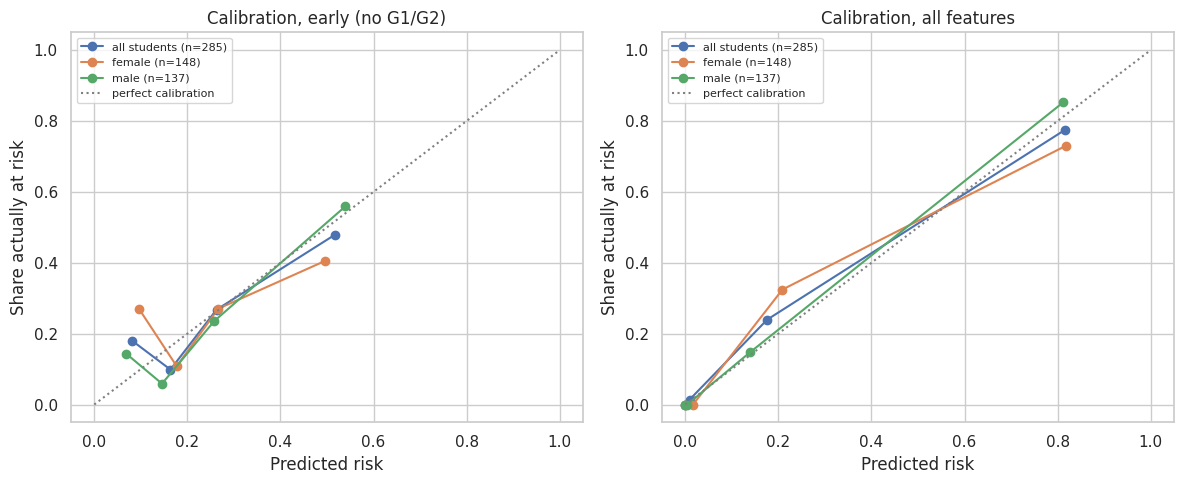


Each point is based on about a quarter of its group, so the lines are noisy, especially for the smaller group.


In [7]:
# Cell 5: calibration, does a predicted risk mean the same thing for everyone?
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, f in zip(axes, feature_sets):
    p = oof_p[(f, "current model")]
    for lab, m in [("all students", np.ones(n, bool)), ("female", attrs["sex"] == 0), ("male", attrs["sex"] == 1)]:
        frac, mean_p = calibration_curve(rv[m], p[m], n_bins=4, strategy="quantile")
        ax.plot(mean_p, frac, "o-", label=f"{lab} (n={int(m.sum())})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="perfect calibration")
    ax.set_xlabel("Predicted risk"); ax.set_ylabel("Share actually at risk")
    ax.set_title(f"Calibration, {f}"); ax.legend(fontsize=8)
    brier, const = brier_score_loss(rv, p), rv.mean() * (1 - rv.mean())
    print(f"{f:18s} Brier score {brier:.3f} vs {const:.3f} for always predicting the overall rate "
          f"(lower is better; improvement {100 * (const - brier) / const:.0f}%)")
plt.tight_layout()
plt.savefig("calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nEach point is based on about a quarter of its group, so the lines are noisy, especially for the smaller group.")

In [8]:
# Cell 6: data minimisation, how few columns do we need? (selection happens INSIDE each fold)
n_rep = 1 if FAST else 3
cv_reg = RepeatedKFold(n_splits=5, n_repeats=n_rep, random_state=42)
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=42)
ks = [1, 2, 3, 5, 8, 12, 20, "all"]

rows, base_rmse, min_k = [], {}, {}
for f, X in feature_sets.items():
    r, c = cfg["regression"][f], cfg["classification"][f]
    base_rmse[f] = -cross_validate(DummyRegressor(), X, y, cv=cv_reg,
                                   scoring="neg_root_mean_squared_error")["test_score"].mean()
    for k in ks:
        kk = X.shape[1] if k == "all" else min(k, X.shape[1])
        reg = Pipeline([("select", SelectKBest(f_regression, k=kk)),
                        ("model", build_reg(r["model"], r["params"]))])
        clf = Pipeline([("select", SelectKBest(f_classif, k=kk)),
                        ("model", build_clf(c["model"], c["params"]))])
        rr = -cross_validate(reg, X, y, cv=cv_reg, scoring="neg_root_mean_squared_error")["test_score"]
        aa = cross_validate(clf, X, y_risk, cv=cv_clf, scoring="roc_auc")["test_score"]
        rows.append({"features": f, "n features": kk, "RMSE": rr.mean(), "RMSE std": rr.std(),
                     "ROC AUC": aa.mean(), "AUC std": aa.std(),
                     "gain over baseline %": 100 * (base_rmse[f] - rr.mean()) / base_rmse[f]})
    print(f"{f} done")

minim = pd.DataFrame(rows).round(3)
for f in feature_sets:
    sub = minim[minim.features == f]
    full_row = sub.loc[sub["n features"].idxmax()]
    ok = sub[(sub["RMSE"] <= full_row["RMSE"] + full_row["RMSE std"]) &
             (sub["ROC AUC"] >= full_row["ROC AUC"] - full_row["AUC std"])]
    min_k[f] = int(ok["n features"].min())
    scores = pd.Series(f_regression(feature_sets[f], y)[0], index=feature_sets[f].columns).sort_values(ascending=False)
    print(f"\n{f}: the smallest set within one std of using all {int(full_row['n features'])} columns has "
          f"{min_k[f]} column(s)")
    print(f"  top columns by simple statistical score (descriptive only): {list(scores.head(6).index)}")
minim

early (no G1/G2) done
all features done

early (no G1/G2): the smallest set within one std of using all 39 columns has 5 column(s)
  top columns by simple statistical score (descriptive only): ['failures', 'absences', 'schoolsup', 'Walc', 'goout', 'Medu']

all features: the smallest set within one std of using all 41 columns has 1 column(s)
  top columns by simple statistical score (descriptive only): ['G2', 'G1', 'failures', 'absences', 'schoolsup', 'Walc']


,features,n features,RMSE,RMSE std,ROC AUC,AUC std,gain over baseline %
0,early (no G1/G2),1,3.141,0.128,0.601,0.059,3.855
1,early (no G1/G2),2,3.155,0.139,0.645,0.077,3.412
2,early (no G1/G2),3,3.123,0.150,0.682,0.068,4.401
3,early (no G1/G2),5,3.054,0.176,0.704,0.057,6.521
4,early (no G1/G2),8,3.020,0.133,0.713,0.059,7.547
5,early (no G1/G2),12,2.986,0.129,0.694,0.052,8.593
6,early (no G1/G2),20,2.951,0.119,0.662,0.075,9.662
7,early (no G1/G2),39,2.952,0.144,0.667,0.081,9.637
8,all features,1,0.843,0.081,0.963,0.022,74.196
9,all features,2,0.827,0.085,0.962,0.025,74.682


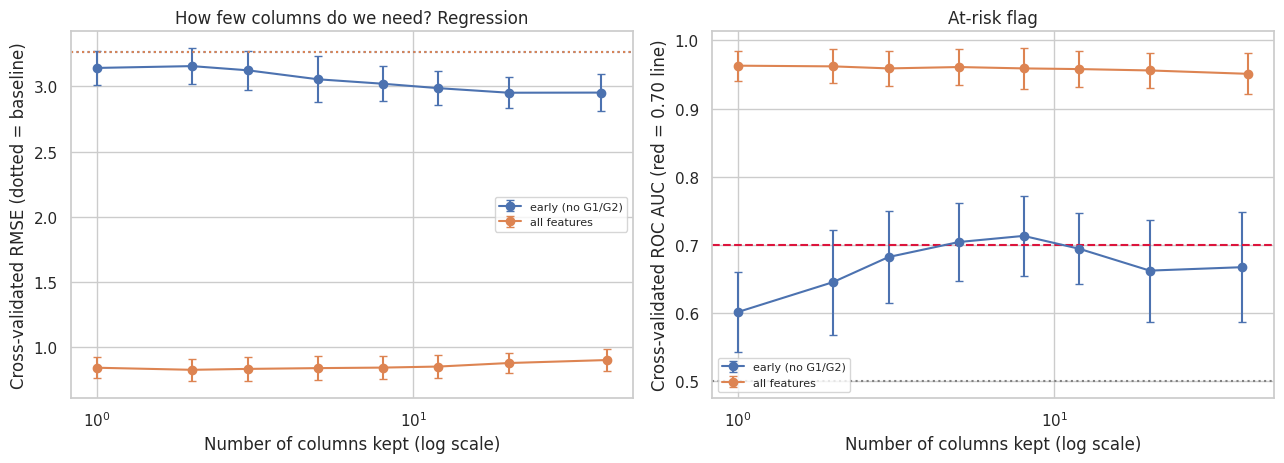

In [9]:
# Cell 7: the minimisation curve
colors = {"early (no G1/G2)": "C0", "all features": "C1"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for f in feature_sets:
    sub = minim[minim.features == f]
    axes[0].errorbar(sub["n features"], sub["RMSE"], yerr=sub["RMSE std"], marker="o", capsize=3,
                     color=colors[f], label=f)
    axes[0].axhline(base_rmse[f], linestyle=":", color=colors[f])
    axes[1].errorbar(sub["n features"], sub["ROC AUC"], yerr=sub["AUC std"], marker="o", capsize=3,
                     color=colors[f], label=f)
axes[0].set_xscale("log"); axes[1].set_xscale("log")
axes[0].set_xlabel("Number of columns kept (log scale)"); axes[0].set_ylabel("Cross-validated RMSE (dotted = baseline)")
axes[0].set_title("How few columns do we need? Regression"); axes[0].legend(fontsize=8)
axes[1].axhline(0.7, color="crimson", linestyle="--"); axes[1].axhline(0.5, color="gray", linestyle=":")
axes[1].set_xlabel("Number of columns kept (log scale)"); axes[1].set_ylabel("Cross-validated ROC AUC (red = 0.70 line)")
axes[1].set_title("At-risk flag"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("data_minimisation.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Cell 8: generate a first draft of the model card from your saved results
def safe_csv(path):
    return pd.read_csv(path) if os.path.exists(path) else None

reg_test, clf_test = safe_csv("test_results_regression.csv"), safe_csv("test_results_classification.csv")
reg_g, clf_g = safe_csv("fairness_regression_gaps.csv"), safe_csv("fairness_classification_gaps.csv")
sizes = safe_csv("fairness_group_sizes.csv")
n_test_rows = len(pd.read_csv("test.csv")) if os.path.exists("test.csv") else None    # row count only

L = ["# Model card: Student Performance Predictor", "",
     "*DRAFT generated from saved results. Replace every [[double-bracket]] item with your own words.*", "",
     "## 1. Purpose and intended use",
     "- Helps a teacher decide which students to check in with. It does not make decisions about students.",
     "- Two models: an EARLY one (before any term grades exist) and a LATER one (after periods 1 and 2).",
     "- Not for: grading, ranking students, admissions, discipline, or any automated decision.", "",
     "## 2. Data",
     f"- UCI Student Performance dataset (maths class), two schools. {n} training students"
     + (f" and {n_test_rows} test students" if n_test_rows else "")
     + ", after removing students with a final grade of 0.",
     "- Target: final grade G3 (0-20). At risk = G3 below 10.",
     "- Students with G3 = 0 were removed because they differ systematically (Day 8). The model says nothing "
     "about students who do not sit the final exam.", "",
     "## 3. Models"]
for f in feature_sets:
    r, c = cfg["regression"][f], cfg["classification"][f]
    L.append(f"- {f}: grade model = {r['model']} (useful vs baseline: {r['useful']}); at-risk flag = {c['model']} "
             f"(usable, AUC >= 0.70: {c['usable']}), threshold {thr[(f, 'current model')]:.2f}.")

L += ["", "## 4. Performance (one-time test evaluation, Day 21)"]
if reg_test is not None and clf_test is not None:
    for _, r_ in reg_test.iterrows():
        L.append(f"- {r_['features']}, grade: test RMSE {r_['test RMSE']} (95% CI {r_['RMSE 95% CI']}); "
                 f"{r_['gain over baseline %']}% better than predicting the average (95% CI {r_['gain 95% CI']}).")
    for _, c_ in clf_test.iterrows():
        L.append(f"- {c_['features']}, flag: test AUC {c_['test AUC']} (95% CI {c_['AUC 95% CI']}); "
                 f"recall {c_['recall']}, precision {c_['precision']}.")
else:
    L.append("- [[Run Day 21 first, test result files not found.]]")

L += ["", "## 5. Fairness audit (training students, out-of-fold predictions)"]
if reg_g is not None and clf_g is not None:
    nd = int((reg_g["worth discussing"].fillna("") != "").sum() + (clf_g["worth discussing"].fillna("") != "").sum())
    L.append(f"- {len(reg_g) + len(clf_g)} group comparisons across 10 attributes; {nd} showed a gap that was both "
             "detectable and practically large (thresholds fixed in advance).")
    if sizes is not None:
        small = int((sizes["small group?"].fillna("") != "").sum())
        L.append(f"- {small} of {len(sizes)} groups were small, so most comparisons cannot rule out a gap.")
L += ["- Mitigation tested (Day 24): dropping sensitive columns and reweighting. [[State what changed beyond noise, if anything.]]",
      "- [[Describe any gap worth discussing, with its group sizes and interval.]]", "",
      "## 6. Data minimisation"]
for f in feature_sets:
    L.append(f"- {f}: {min_k[f]} column(s) perform within one standard deviation of using all "
             f"{feature_sets[f].shape[1]}. [[State what this means for what a school should collect.]]")

L += ["", "## 7. Limitations",
      "- Small data: a few hundred students, and about a quarter at risk, so every estimate has wide intervals.",
      "- Two schools in one country, collected years ago, one subject. Patterns may not transfer.",
      "- The early model adds little over predicting the class average [[confirm with your own results]].",
      "- Students with a final grade of 0 are excluded.",
      "- Groups are recorded coarsely (for example sex as two values), and many are too small to audit.",
      "- Explanations describe what the model uses to predict, not what causes grades.", "",
      "## 8. Ethical considerations and use policy (recommended, edit to your own judgement)",
      "- A flag starts a conversation. It is never a decision, a label, or a reason to restrict a student.",
      "- Human review of every flag; tell students and guardians that the tool exists and how it is used.",
      "- Do not use for grading, ranking, admissions or discipline.",
      "- Collect only the columns the task needs (Section 6), and keep them only as long as they are needed.",
      "- Restrict access; do not paste real student data into public AI tools.",
      "- Re-run the fairness audit and the calibration check every term.",
      "- [[State when you would stop using the tool, for example if recall on new students falls below a level you set.]]",
      "- Check the data-protection law that applies where the tool would be used. This card is not legal advice.", ""]

open("MODEL_CARD.md", "w").write("\n".join(L))
print("\n".join(L))

# Model card: Student Performance Predictor

*DRAFT generated from saved results. Replace every [[double-bracket]] item with your own words.*

## 1. Purpose and intended use
- Helps a teacher decide which students to check in with. It does not make decisions about students.
- Two models: an EARLY one (before any term grades exist) and a LATER one (after periods 1 and 2).
- Not for: grading, ranking students, admissions, discipline, or any automated decision.

## 2. Data
- UCI Student Performance dataset (maths class), two schools. 285 training students, after removing students with a final grade of 0.
- Target: final grade G3 (0-20). At risk = G3 below 10.
- Students with G3 = 0 were removed because they differ systematically (Day 8). The model says nothing about students who do not sit the final exam.

## 3. Models
- early (no G1/G2): grade model = Ridge (useful vs baseline: False); at-risk flag = Logistic (usable, AUC >= 0.70: False), threshold 0.12.
- all features: grade model = Rid